# Layer Normalization: How It Works, and How It Helps Learning

The previous notebook opened up **BatchNorm** (BN). BN normalizes each unit **across the examples of a mini-batch**, which makes an example's output depend on its batch-mates and forces a train/eval split. **Layer Normalization** (LN, Ba et al., 2016) normalizes in the other direction: each *example* is normalized **across its own units**. Nothing is shared between examples, so there is no batch dependence, no running statistics, and the same computation at train and test time. LN is the default normalizer in Transformers and recurrent networks, where batch statistics are awkward.

```
 activations of one layer:  rows = examples in the batch, columns = units

                  unit 1   unit 2   unit 3   ...   unit d
   example 1  [    .        .        .       ...     .    ]  --> LayerNorm: mean/std of THIS ROW
   example 2  [    .        .        .       ...     .    ]  --> LayerNorm: mean/std of THIS ROW
   example 3  [    .        .        .       ...     .    ]  --> LayerNorm: mean/std of THIS ROW
                   |        |        |               |
                   v        v        v               v
               BatchNorm: mean/std of THIS COLUMN (over the batch)

   z_hat = (z - mean) / sqrt(var + eps)      out = gamma * z_hat + beta     (gamma, beta: learned, one per unit)
```

The only difference to BN is **which axis the mean and variance are computed over**, but that changes what the layer is invariant to, when it works, and how much it helps.

**What you will do**

1. Implement LayerNorm from scratch and check it against `nn.LayerNorm`
2. See, on a toy matrix, what normalizing rows (LN) instead of columns (BN) does
3. Find out **exactly what LN is invariant to**, with a controlled experiment against plain and BN layers
4. Check LN's **scale invariance** and what it does to gradients
5. Train deep networks with plain / BN / LN layers: **drift, initialization, learning rate**, and a result about how **weight scale acts like a learning rate**
6. See what LN buys that BN cannot: **independence from the batch** and **robustness to per-example input scale**
7. Put it in perspective, honestly: where LN helps, and where BN is still ahead

Everything runs on CPU in about 5 minutes.

## 0. Setup

In [1]:
import copy
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 0


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)          # tiny networks run fastest single-threaded on CPU
print("torch", torch.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# Same data and split as the BatchNorm notebook: scikit-learn digits (8x8 images, 10 classes)
digits = load_digits()
Xd = (digits.data / 16.0).astype(np.float32)
yd = digits.target.astype(np.int64)
X_tr, X_rest, y_tr, y_rest = train_test_split(Xd, yd, train_size=1000, stratify=yd, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, train_size=400, stratify=y_rest, random_state=SEED)
print(f"train={len(X_tr)}  val={len(X_va)}  test={len(X_te)}")

Xtr_t, ytr_t = torch.tensor(X_tr), torch.tensor(y_tr)
Xva_t, yva_t = torch.tensor(X_va), torch.tensor(y_va)
Xte_t, yte_t = torch.tensor(X_te), torch.tensor(y_te)
PROBE_X, PROBE_Y = Xtr_t[:256], ytr_t[:256]       # a fixed batch used to *observe* networks
loss_fn = nn.CrossEntropyLoss()

NAMES = {"none": "plain", "bn": "BatchNorm", "ln": "LayerNorm"}
COL = {"none": "C3", "bn": "C0", "ln": "C2"}

torch 2.15.0+cu132
train=1000  val=400  test=397


## 1. The LayerNorm operation, from scratch

For one example with pre-activations `z` (a vector of `d` units), LN computes:

1. `mu = mean(z)` and `var = mean((z - mu)^2)`, **over the units of this one example**
2. `z_hat = (z - mu) / sqrt(var + eps)`: this example's activations now have mean 0 and variance 1 across units
3. `out = gamma * z_hat + beta`, with learned per-unit `gamma` and `beta`

There is **no running average** and **no momentum**: the statistics come from the example itself, in training and at inference alike.

In [2]:
class ScratchLayerNorm(nn.Module):
    def __init__(self, num_features, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(num_features))
        self.beta = nn.Parameter(torch.zeros(num_features))

    def forward(self, x):
        mu = x.mean(-1, keepdim=True)                     # one mean per example (over the last axis = units)
        var = x.var(-1, unbiased=False, keepdim=True)
        x_hat = (x - mu) / torch.sqrt(var + self.eps)
        return self.gamma * x_hat + self.beta

### 1a. Check it against PyTorch, and against BatchNorm's behaviour

As for BN, we compare outputs and gradients (float64, random `gamma`/`beta`) to the PyTorch layer. Then three properties that follow directly from the definition: the layer behaves **identically in `train()` and `eval()`** mode, an example's output **does not depend on the other examples in the batch**, and, for contrast, BN does depend on them.

In [3]:
torch.manual_seed(0)
C = 5
mine, ref = ScratchLayerNorm(C).double(), nn.LayerNorm(C).double()
with torch.no_grad():
    g, b = torch.randn(C).double() + 1.5, torch.randn(C).double()
    mine.gamma.copy_(g); mine.beta.copy_(b); ref.weight.copy_(g); ref.bias.copy_(b)

x1 = (torch.randn(32, C) * 3 + 2).double().requires_grad_()
x2 = x1.detach().clone().requires_grad_()
w = torch.randn(32, C).double()                      # arbitrary upstream gradient
o1, o2 = mine(x1), ref(x2)
(o1 * w).sum().backward(); (o2 * w).sum().backward()

rows = [("forward output", (o1 - o2).abs().max()),
        ("grad wrt input", (x1.grad - x2.grad).abs().max()),
        ("grad wrt gamma", (mine.gamma.grad - ref.weight.grad).abs().max()),
        ("grad wrt beta", (mine.beta.grad - ref.bias.grad).abs().max())]
print(f"{'quantity':<22} {'max |difference|':>18}")
for name, d in rows:
    print(f"{name:<22} {d.item():>18.2e}")

xt = (torch.randn(8, C) * 3 + 2).double()
bn = nn.BatchNorm1d(C).double()
with torch.no_grad():
    mine.train(); a = mine(xt); mine.eval(); b_ = mine(xt)
    alone = mine(xt[:1])                                      # example 0 on its own
    bn.train(); bn_batch = bn(xt)[:1]
    bn_other = bn(torch.cat([xt[:1], xt[4:5] * 10]))[:1]      # example 0 with a different batch-mate
print(f"\nLN: train-mode output vs eval-mode output          max |diff| = {(a - b_).abs().max().item():.1e}")
print(f"LN: example 0 alone vs inside a batch of 8          max |diff| = {(alone - a[:1]).abs().max().item():.1e}")
print(f"BN: example 0 with two different batch-mates         max |diff| = {(bn_batch - bn_other).abs().max().item():.2f}   (it depends on the batch)")
print("\nper-example mean / std of the normalized output (before gamma and beta), first 4 examples:")
xh = (mine(xt) - mine.beta) / mine.gamma
print("  mean:", xh.mean(1)[:4].detach().numpy().round(6), "  std:", xh.std(1, unbiased=False)[:4].detach().numpy().round(4))

quantity                 max |difference|
forward output                   8.88e-16
grad wrt input                   1.78e-15
grad wrt gamma                   5.33e-15
grad wrt beta                    0.00e+00

LN: train-mode output vs eval-mode output          max |diff| = 0.0e+00
LN: example 0 alone vs inside a batch of 8          max |diff| = 0.0e+00
BN: example 0 with two different batch-mates         max |diff| = 1.91   (it depends on the batch)

per-example mean / std of the normalized output (before gamma and beta), first 4 examples:
  mean: [ 0. -0. -0.  0.]   std: [1. 1. 1. 1.]


**Reading the output.** The scratch layer matches PyTorch to machine precision in the forward pass and in all three gradients. Each normalized example has mean 0 and standard deviation 1 across its units. The three properties are exact, not approximate: train and eval give identical outputs, example 0 gives the same output alone as inside a batch, whereas BN's output for example 0 changes by up to 1.9 when only its batch-mates change. That batch coupling is what LN removes.

## 2. Rows or columns? What the normalization axis changes

Take a small matrix of pre-activations (12 examples x 16 units) that has two kinds of irregularity, typical of what happens inside a network: **each unit has its own offset** (columns differ) and **each example has its own overall scale** (rows differ). We normalize it over columns (BN) and over rows (LN) and look at what is left.

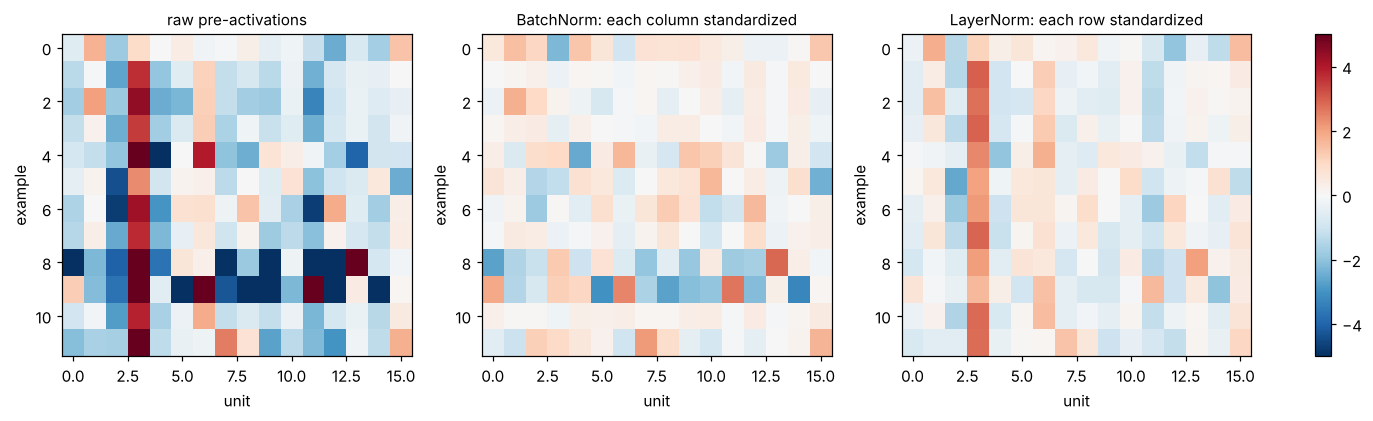

                         per-UNIT stats (columns): max |mean|, std range      per-EXAMPLE stats (rows): max |mean|, std range
raw                         4.145   [0.81, 2.95]                                1.895   [1.11, 4.78]
BatchNorm                   0.000   [1.00, 1.00]                                0.591   [0.19, 1.92]
LayerNorm                   2.384   [0.39, 0.88]                                0.000   [1.00, 1.00]


In [4]:
rng = np.random.default_rng(1)
core = rng.standard_normal((12, 16))
row_scale = np.exp(rng.normal(0, 0.8, (12, 1)))            # per-example scale (e.g. image contrast)
col_offset = rng.normal(0, 2.0, (1, 16))                    # per-unit offset
A = torch.tensor(core * row_scale + col_offset, dtype=torch.float32)
A_bn = F.batch_norm(A, None, None, training=True)           # normalize each COLUMN
A_ln = F.layer_norm(A, (16,))                               # normalize each ROW

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, M) in zip(axes, (("raw pre-activations", A), ("BatchNorm: each column standardized", A_bn), ("LayerNorm: each row standardized", A_ln))):
    im = ax.imshow(M.numpy(), cmap="RdBu_r", vmin=-5, vmax=5, aspect="auto"); ax.grid(False)
    ax.set_title(title, fontsize=10); ax.set_xlabel("unit"); ax.set_ylabel("example")
plt.colorbar(im, ax=axes, fraction=0.02)
plt.show()

stat = lambda M, dim: (M.mean(dim).abs().max().item(), M.std(dim, unbiased=False).min().item(), M.std(dim, unbiased=False).max().item())
print(f"{'':<24} {'per-UNIT stats (columns): max |mean|, std range':<52} {'per-EXAMPLE stats (rows): max |mean|, std range'}")
for name, M in (("raw", A), ("BatchNorm", A_bn), ("LayerNorm", A_ln)):
    c, r = stat(M, 0), stat(M, 1)
    print(f"{name:<24} {c[0]:>8.3f}   [{c[1]:.2f}, {c[2]:.2f}]{'':<28} {r[0]:>8.3f}   [{r[1]:.2f}, {r[2]:.2f}]")

**Reading the heatmap and the table.** Raw, the matrix has uneven columns (per-unit means up to 4.1 in magnitude) and uneven rows (per-example std from 1.1 to 4.8).

- **BatchNorm** makes every *column* exactly mean 0 / std 1, but the rows stay uneven (std from 0.19 to 1.92): an example with a large overall scale is still large.
- **LayerNorm** makes every *row* exactly mean 0 / std 1, but the columns stay uneven (per-unit means up to 2.4, stds from 0.39 to 0.88): the per-unit offsets survive.

Neither fixes everything; each fixes the statistic along its own axis. Which of those the network cares about is what the rest of the notebook probes.

### 2b. Does LN also rescue a saturated unit?

In the BN notebook we built a layer whose pre-activations were pushed far from zero (large weights, per-unit offsets) and saw that 37% of the `tanh` activations were saturated and BN brought that down to 3%. Same layer, same data, now with LN as well. We show the most displaced unit and count the saturated activations over the whole layer.

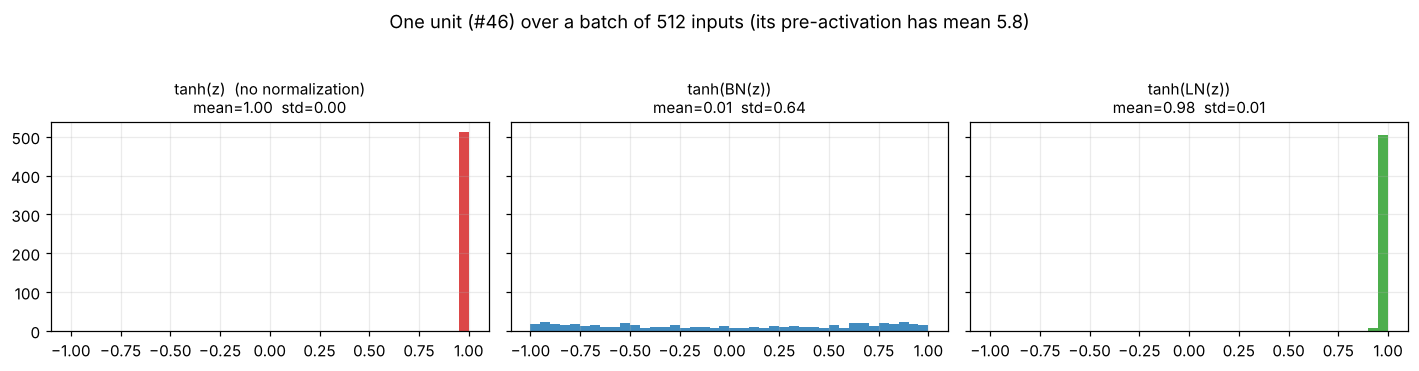

Fraction of ALL 64 units x 512 samples with |tanh| > 0.97 (saturated):
   no normalization: 37.0%     BatchNorm: 3.0%     LayerNorm: 5.1%

mean over examples of the row std of Z: 2.43;  std of the per-unit means of Z (the offsets): 2.29


In [5]:
set_seed()
lin = nn.Linear(64, 64)
with torch.no_grad():
    nn.init.xavier_uniform_(lin.weight, gain=3.0)         # large weights ...
    lin.bias.copy_(torch.randn(64) * 2.0)                 # ... and per-unit offsets
Z = lin(Xtr_t[:512]).detach()                             # pre-activations [512, 64]
Zbn = F.batch_norm(Z, None, None, training=True)
Zln = F.layer_norm(Z, (64,))
u = int(Z.mean(0).abs().argmax())                         # the most displaced unit

panels = [("tanh(z)  (no normalization)", torch.tanh(Z[:, u])), ("tanh(BN(z))", torch.tanh(Zbn[:, u])), ("tanh(LN(z))", torch.tanh(Zln[:, u]))]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (title, v), c in zip(axes, panels, ("C3", "C0", "C2")):
    ax.hist(v.numpy(), bins=40, range=(-1, 1), color=c, alpha=0.85)
    ax.set_title(f"{title}\nmean={v.mean():.2f}  std={v.std():.2f}", fontsize=10)
plt.suptitle(f"One unit (#{u}) over a batch of 512 inputs (its pre-activation has mean {Z[:, u].mean():.1f})", y=1.04)
plt.tight_layout(); plt.show()

sat = lambda h: (h.abs() > 0.97).float().mean().item()
print("Fraction of ALL 64 units x 512 samples with |tanh| > 0.97 (saturated):")
print(f"   no normalization: {sat(torch.tanh(Z)):.1%}     BatchNorm: {sat(torch.tanh(Zbn)):.1%}     LayerNorm: {sat(torch.tanh(Zln)):.1%}")
print(f"\nmean over examples of the row std of Z: {Z.std(1).mean():.2f};  std of the per-unit means of Z (the offsets): {Z.mean(0).std():.2f}")

**Reading it.** LN does take the saturated fraction from 37% down to 5.1% (BN: 3.0%), so it also pulls this badly scaled layer back into `tanh`'s active range. It is slightly worse than BN, and the reason is visible in the last line: the per-unit offsets (std 2.3) are about as large as the row spread (2.4). LN removes only the part of an offset that is *shared* by all units of an example, so what is left in individual units is not centred; BN centres each unit separately.

## 3. Exactly what is LN invariant to?

As in the BN notebook, take two layers; layer 1 turns the data into `h1 = tanh(norm(W x + b))`, which is layer 2's input. We perturb layer 1 in four ways and measure **how much `h1` changes**, as the relative distance `||h1' - h1|| / ||h1||` (0 means exactly invariant). Plain `tanh`, BN and LN layers are all put through the same tests.

- **(i) rescale the weights:** `W -> s * W`
- **(ii) shift the bias by a random vector:** `b -> b + d * direction` (every unit shifted by a different amount)
- **(iii) shift the bias by a constant:** `b -> b + c * (1, 1, ..., 1)` (every unit shifted by the *same* amount)
- **(iv) rescale each input example by its own random factor:** `x_i -> s_i * x_i`, with `s_i = exp(rho * N(0,1))`; think of images with different brightness or contrast

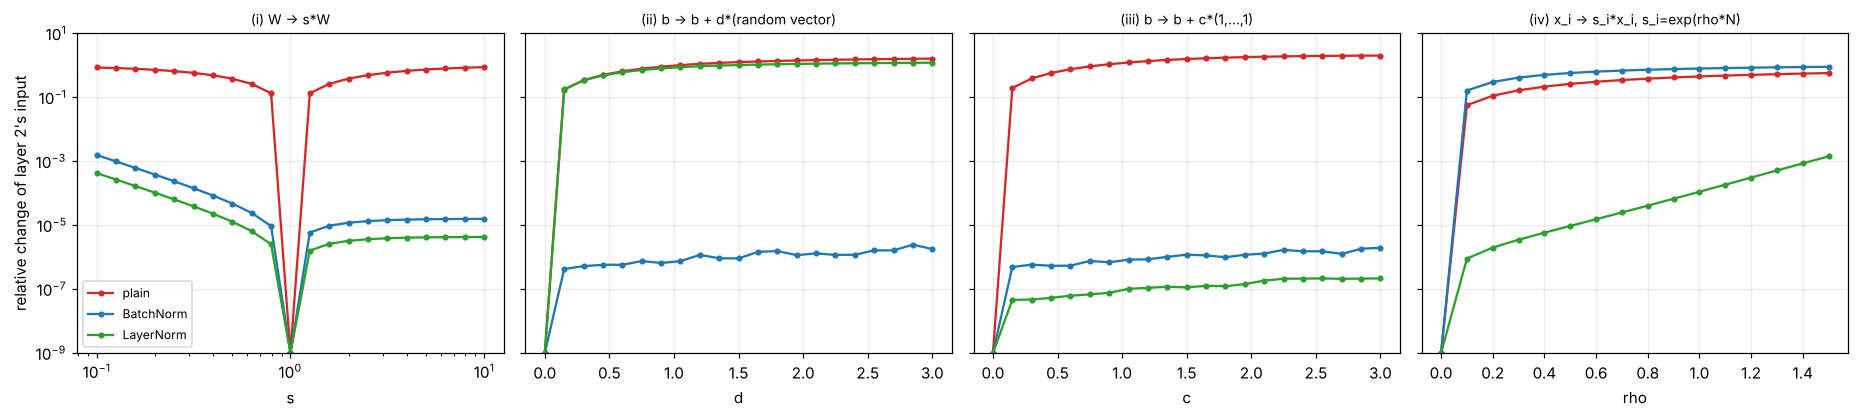

perturbation                                  plain    BatchNorm    LayerNorm     (largest relative change; 'inv' = below 1e-2)
(i) W -> s*W                            8.9e-01      1.6e-03 inv  4.3e-04 inv
(ii) b -> b + d*(random vector)         1.6e+00      2.5e-06 inv  1.2e+00    
(iii) b -> b + c*(1,...,1)              2.0e+00      2.0e-06 inv  2.2e-07 inv
(iv) x_i -> s_i*x_i, s_i=exp(rho*N)     5.8e-01      9.1e-01      1.4e-03 inv


In [6]:
g = torch.Generator().manual_seed(0)
bound = np.sqrt(6.0 / (64 + 64))
W0 = (torch.rand(64, 64, generator=g) * 2 - 1) * bound * nn.init.calculate_gain("tanh")
b_dir = torch.randn(64, generator=g)
ex_noise = torch.randn(len(PROBE_X), 1, generator=g)      # fixed random draw for the per-example scales


def layer_out(W, b, X, kind):
    z = X @ W.T + b
    if kind == "bn":
        z = F.batch_norm(z, None, None, training=True)
    elif kind == "ln":
        z = F.layer_norm(z, (64,))
    return torch.tanh(z)


rel = lambda h, h0: ((h - h0).norm() / h0.norm()).item()
Z0 = torch.zeros(64)
tests = {
    "(i) W -> s*W":                        (torch.logspace(-1, 1, 21),  lambda s: (W0 * s, Z0, PROBE_X), "s"),
    "(ii) b -> b + d*(random vector)":      (torch.linspace(0, 3, 21),   lambda d: (W0, d * b_dir, PROBE_X), "d"),
    "(iii) b -> b + c*(1,...,1)":           (torch.linspace(0, 3, 21),   lambda c: (W0, c * torch.ones(64), PROBE_X), "c"),
    "(iv) x_i -> s_i*x_i, s_i=exp(rho*N)":  (torch.linspace(0, 1.5, 16), lambda r: (W0, Z0, PROBE_X * torch.exp(r * ex_noise)), "rho"),
}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
worst = {}
for ax, (title, (grid, make, sym)) in zip(axes, tests.items()):
    for kind in ("none", "bn", "ln"):
        h0 = layer_out(W0, Z0, PROBE_X, kind)
        ch = np.array([rel(layer_out(*make(v), kind), h0) for v in grid])
        worst[(title, kind)] = ch.max()
        ax.plot(grid, np.maximum(ch, 1e-9), marker="o", ms=3, color=COL[kind], label=NAMES[kind])
    ax.set_yscale("log"); ax.set_title(title, fontsize=9); ax.set_xlabel(sym)
    if sym == "s": ax.set_xscale("log")
axes[0].set_ylabel("relative change of layer 2's input"); axes[0].legend(fontsize=8); axes[0].set_ylim(1e-9, 10)
plt.tight_layout(); plt.show()

print(f"{'perturbation':<38} " + " ".join(f"{NAMES[k]:>12}" for k in ("none", "bn", "ln")) + "     (largest relative change; 'inv' = below 1e-2)")
for title in tests:
    cells_ = []
    for kind in ("none", "bn", "ln"):
        v = worst[(title, kind)]
        cells_.append(f"{v:>8.1e}{' inv' if v < 1e-2 else '    '}")
    print(f"{title:<38} " + " ".join(f"{c:>12}" for c in cells_))

**Reading the table** (an entry is "inv" when the output changes by less than 1%; the small residual of 1e-3 for (i) comes from the `eps` in the denominator):

| perturbation | plain | BatchNorm | LayerNorm |
|---|---|---|---|
| (i) rescale `W` | changes | invariant | **invariant** |
| (ii) random-vector bias shift | changes | invariant | **changes (1.2)** |
| (iii) constant bias shift | changes | invariant | **invariant** |
| (iv) per-example input scale | changes | **changes (0.91)** | **invariant** |

The two normalizers are invariant to *different* things. BN removes any per-unit offset and any weight scale, but it does not undo a per-example scale: multiplying one example's input shifts that example's pre-activations relative to the batch statistics. LN is the mirror image: it cancels a per-example scale and a shift shared by all units, but a bias vector with different values per unit passes straight through (panel ii). This is the main thing to remember about the two methods, and the experiments below follow from it.

## 4. A deep network, and LN's scale invariance

The networks we will train are the same family as in the BN notebook: an MLP with 8 hidden layers of 64 `tanh` units, with three block types:

| Name | Block |
|---|---|
| **plain** | `Linear -> tanh` |
| **BatchNorm** | `Linear (no bias) -> BatchNorm1d -> tanh` |
| **LayerNorm** | `Linear (no bias) -> LayerNorm -> tanh` |

The bias is dropped in front of a normalizer: BN subtracts it exactly, and while LN does not cancel a *vector* bias (section 3, panel ii), `beta` plays that role. `init_gain` multiplies the Xavier-`tanh` initialization of the hidden layers, so we can ask how sensitive each network is to a badly scaled initialization.

The training loop is the one from the BN notebook, SGD with momentum 0.9 and batch size 64. Every few steps it also pushes a fixed batch through a copy of the network and records **two kinds of statistics** of each block's output (the next layer's input): the **per-unit** statistics over the batch (what BN controls) and the **per-example** statistics over the units (what LN controls).

In [7]:
class DeepMLP(nn.Module):
    def __init__(self, norm="none", depth=8, width=64, in_dim=64, out_dim=10, init_gain=1.0):
        super().__init__()
        blocks, d = [], in_dim
        for _ in range(depth):
            layers = [nn.Linear(d, width, bias=(norm == "none"))]
            if norm == "bn":
                layers.append(nn.BatchNorm1d(width))
            elif norm == "ln":
                layers.append(nn.LayerNorm(width))
            layers.append(nn.Tanh())
            blocks.append(nn.Sequential(*layers))
            d = width
        self.blocks = nn.ModuleList(blocks)
        self.head = nn.Linear(width, out_dim)
        for blk in self.blocks:
            nn.init.xavier_uniform_(blk[0].weight, gain=nn.init.calculate_gain("tanh") * init_gain)
        nn.init.xavier_uniform_(self.head.weight)
        nn.init.zeros_(self.head.bias)
        for m in self.modules():
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x, return_acts=False):
        hs = [x]                                  # hs[j] = output of block j (hs[0] is the data)
        for blk in self.blocks:
            x = blk(x); hs.append(x)
        out = self.head(x)
        return (out, hs) if return_acts else out


def new_model(norm, seed=0, **kw):
    set_seed(seed)
    return DeepMLP(norm, **kw)


val_loader_X, val_loader_y = Xva_t, yva_t


@torch.no_grad()
def evaluate(model, X=Xva_t, y=yva_t):
    model.eval()
    out = model(X)
    return F.cross_entropy(out, y).item(), (out.argmax(1) == y).float().mean().item()


def fit(model, epochs=15, lr=0.05, momentum=0.9, batch_size=64, seed=0, probe_every=None, wlayer=3):
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader_gen = torch.Generator().manual_seed(seed)
    h = dict(train_loss=[], val_loss=[], val_acc=[], wnorm=[], probe_steps=[], unit_mu=[], unit_sd=[], ex_sd=[], diverged=False)
    step = 0
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t), generator=loader_gen)
        ep = []
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            if probe_every and step % probe_every == 0:
                with torch.no_grad():
                    _, hs = copy.deepcopy(model).train()(PROBE_X, return_acts=True)
                h["probe_steps"].append(step)
                h["unit_mu"].append(np.stack([a.mean(0).numpy() for a in hs[1:]]))               # per-unit mean over the batch  [blocks, units]
                h["unit_sd"].append(np.stack([a.std(0).numpy() for a in hs[1:]]))                # per-unit std over the batch
                h["ex_sd"].append(np.stack([a.std(1).numpy() for a in hs[1:]]).mean(1))          # per-example std over units, averaged over examples [blocks]
            opt.zero_grad()
            loss = loss_fn(model(Xtr_t[idx]), ytr_t[idx])
            if not torch.isfinite(loss):
                h["diverged"] = True
                break
            loss.backward(); opt.step()
            ep.append(loss.item()); step += 1
        if h["diverged"]:
            break
        vl, va = evaluate(model)
        h["train_loss"].append(float(np.mean(ep))); h["val_loss"].append(vl); h["val_acc"].append(va)
        h["wnorm"].append(model.blocks[wlayer][0].weight.norm().item())
    missing = epochs - len(h["val_acc"])
    if missing:                                                # pad a diverged run so curves line up
        _, va = evaluate(model)
        h["train_loss"] += [np.nan] * missing; h["val_loss"] += [np.nan] * missing
        h["val_acc"] += [va] * missing; h["wnorm"] += [np.nan] * missing
    return h


print(new_model("ln").blocks[0])

Sequential(
  (0): Linear(in_features=64, out_features=64, bias=False)
  (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (2): Tanh()
)


### 4a. Scale invariance and what it does to gradients

Panel (i) of section 3 showed that LN's output does not change when the preceding weights are rescaled (LN divides out the scale of each example's pre-activations). So, just as for BN, the **loss is unchanged** when a weight matrix in front of an LN layer is multiplied by `c`, which implies: the **gradient is perpendicular to the weights**, and **its norm shrinks as `1/c`**. We check it on block 4 of networks trained for 5 epochs, for all three block types.

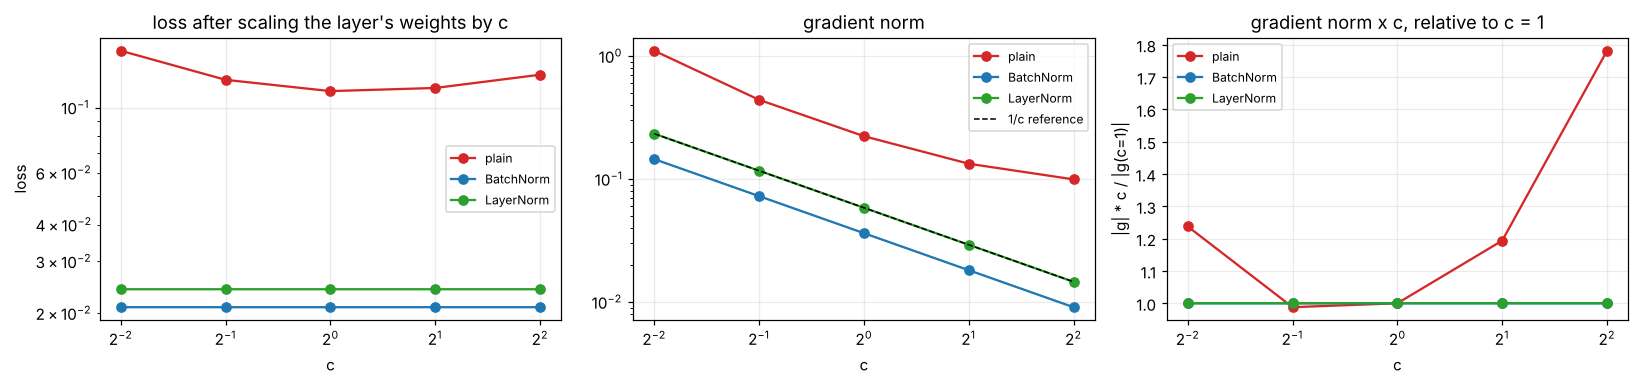

    c |              plain              |            BatchNorm            |            LayerNorm           
      |      loss      |g|*c       cos |      loss      |g|*c       cos |      loss      |g|*c       cos
 0.25 |   0.15603     0.2761  -1.5e-02 |   0.02095     0.0363  -1.6e-06 |   0.02411     0.0584  -8.6e-07
  0.5 |   0.12426     0.2204  -1.0e-02 |   0.02095     0.0363  -3.9e-07 |   0.02411     0.0584  -2.1e-07
  1.0 |   0.11375     0.2231  -7.0e-04 |   0.02095     0.0363  -9.4e-08 |   0.02411     0.0584  -4.7e-08
  2.0 |   0.11658     0.2663   2.8e-03 |   0.02095     0.0363  -2.4e-08 |   0.02411     0.0584  -1.1e-08
  4.0 |   0.12933     0.3974   4.3e-03 |   0.02095     0.0363   7.5e-09 |   0.02411     0.0584  -4.7e-09


In [8]:
def loss_and_grad(model, k, c):
    m = copy.deepcopy(model).train()
    W = m.blocks[k][0].weight
    with torch.no_grad():
        W.mul_(c)
    loss = loss_fn(m(PROBE_X), PROBE_Y)
    g, = torch.autograd.grad(loss, W)
    return loss.item(), g.norm().item(), F.cosine_similarity(g.flatten(), W.detach().flatten(), dim=0).item()


cs = [0.25, 0.5, 1.0, 2.0, 4.0]
warm = {nm: new_model(nm) for nm in NAMES}
for m in warm.values():
    fit(m, epochs=5, lr=0.05)
inv = {nm: np.array([loss_and_grad(warm[nm], 3, c) for c in cs]) for nm in NAMES}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for nm in NAMES:
    axes[0].plot(cs, inv[nm][:, 0], marker="o", color=COL[nm], label=NAMES[nm])
    axes[1].plot(cs, inv[nm][:, 1], marker="o", color=COL[nm], label=NAMES[nm])
    axes[2].plot(cs, inv[nm][:, 1] * np.array(cs) / inv[nm][2, 1], marker="o", color=COL[nm], label=NAMES[nm])
axes[1].plot(cs, inv["ln"][2, 1] / np.array(cs), "k--", lw=1, label="1/c reference")
axes[0].set_title("loss after scaling the layer's weights by c"); axes[0].set_ylabel("loss"); axes[0].set_yscale("log")
axes[1].set_title("gradient norm"); axes[1].set_yscale("log")
axes[2].set_title("gradient norm x c, relative to c = 1"); axes[2].set_ylabel("|g| * c / |g(c=1)|")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xlabel("c"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'c':>5} | " + " | ".join(f"{NAMES[nm]:^31}" for nm in NAMES))
print(f"{'':>5} | " + " | ".join(f"{'loss':>9} {'|g|*c':>10} {'cos':>9}" for _ in NAMES))
for i, c in enumerate(cs):
    print(f"{c:>5} | " + " | ".join(f"{inv[nm][i, 0]:>9.5f} {inv[nm][i, 1] * c:>10.4f} {inv[nm][i, 2]:>9.1e}" for nm in NAMES))

**Reading it.** For BN and LN the loss is identical for every `c` (0.02095 and 0.02411), the gradient is perpendicular to the weights (cosine ~1e-7 or smaller), and `|g| * c` is constant, i.e. the gradient norm shrinks as `1/c`. The plain network has none of these properties: its loss changes with `c` (0.114 to 0.156), the gradient is not orthogonal to `W`, and `|g| * c` varies by almost 2x.

Consequence (the same as for BN): a weight matrix in front of a normalizer has a **self-adjusting step size**. If its norm grows, its gradient shrinks and the effective learning rate `lr / ||W||^2` falls. Section 5d uses this to explain an initialization result.

## 5. Training: does LN tame the drift and make learning easier?

### 5a. Watching the layer statistics during training

All three networks train at `lr = 0.1`. We plot, for the outputs of blocks 2, 4, 6 and 8 (the inputs of the following layers), three statistics on the fixed probe batch: the **per-unit** mean magnitude and **per-unit** spread over the batch (BN's currency), and the **per-example** spread across units (LN's currency). The BN notebook's drift score is also computed for the per-unit means.

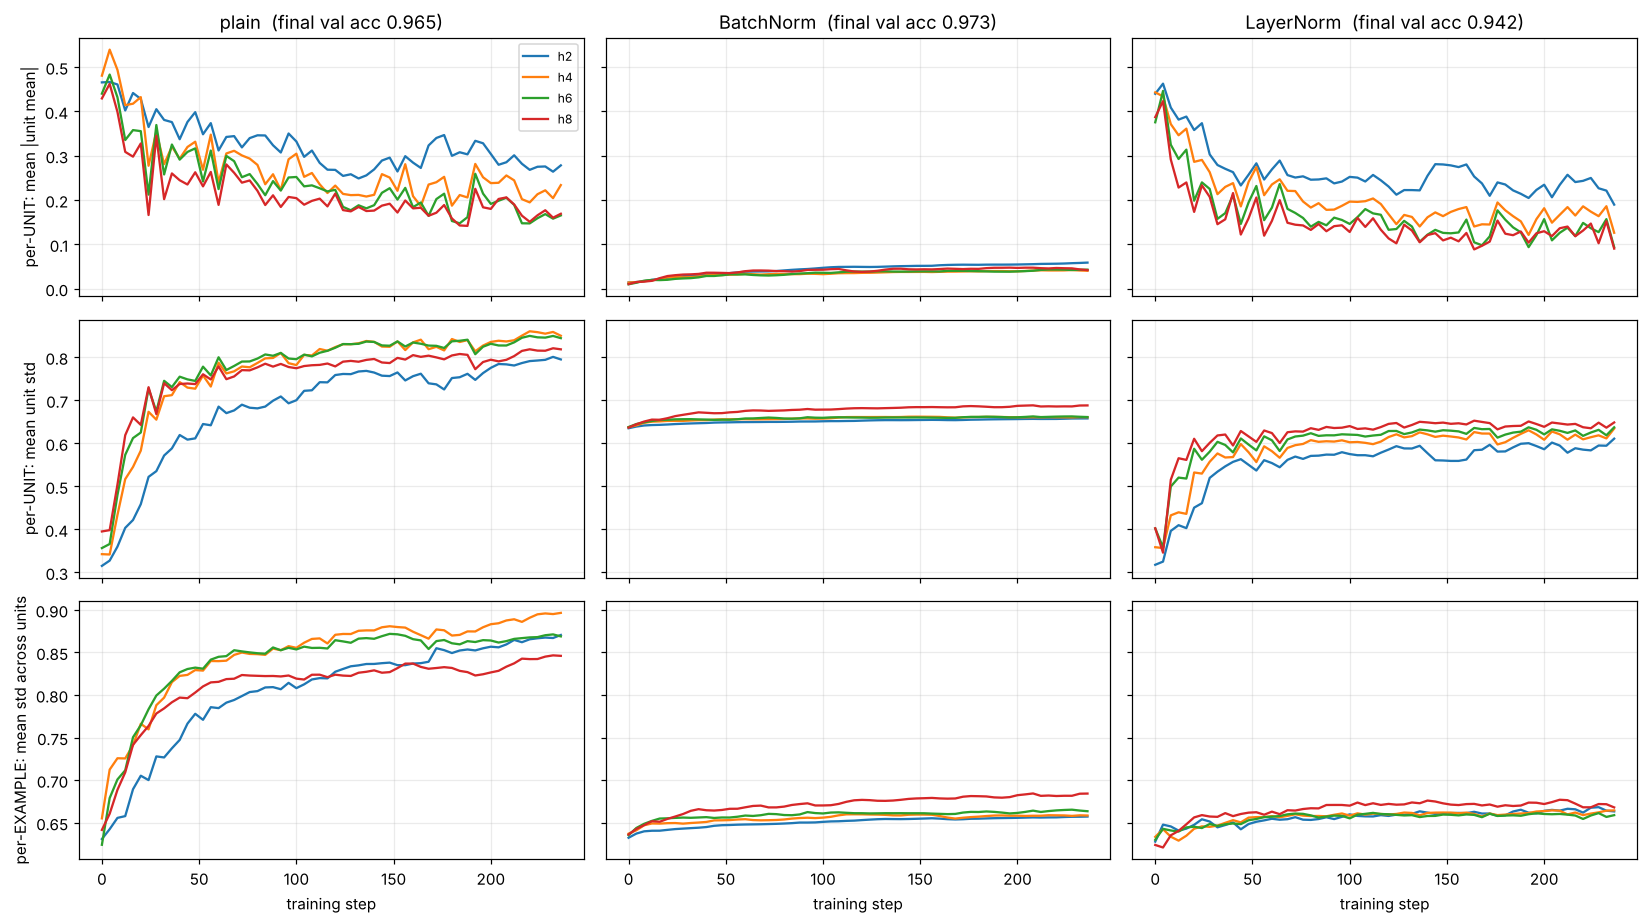

               per-unit drift score    per-example spread: relative change per probe
plain                        0.1642                                           0.0066
BatchNorm                    0.0068                                           0.0012
LayerNorm                    0.1826                                           0.0031


In [9]:
LR_OBS = 0.1
obs = {nm: fit(new_model(nm), epochs=15, lr=LR_OBS, probe_every=4) for nm in NAMES}

sel = [2, 4, 6, 8]
fig, axes = plt.subplots(3, 3, figsize=(15, 8.5), sharex=True, sharey="row")
for col, nm in enumerate(NAMES):
    o = obs[nm]; steps = np.array(o["probe_steps"]); mu = np.stack(o["unit_mu"]); sd = np.stack(o["unit_sd"]); ex = np.stack(o["ex_sd"])
    for L in sel:
        axes[0, col].plot(steps, np.abs(mu[:, L - 1, :]).mean(1), label=f"h{L}")
        axes[1, col].plot(steps, sd[:, L - 1, :].mean(1), label=f"h{L}")
        axes[2, col].plot(steps, ex[:, L - 1], label=f"h{L}")
    axes[0, col].set_title(f"{NAMES[nm]}  (final val acc {o['val_acc'][-1]:.3f})"); axes[2, col].set_xlabel("training step")
axes[0, 0].set_ylabel("per-UNIT: mean |unit mean|"); axes[1, 0].set_ylabel("per-UNIT: mean unit std"); axes[2, 0].set_ylabel("per-EXAMPLE: mean std across units")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()


def drift_unit(o):
    mu, sd = np.stack(o["unit_mu"]), np.stack(o["unit_sd"])
    return (np.abs(np.diff(mu, axis=0)) / (sd.mean(0)[None] + 1e-6)).mean()


def drift_example(o):
    ex = np.stack(o["ex_sd"])                                   # [probes, blocks]
    return (np.abs(np.diff(ex, axis=0)) / (ex.mean(0)[None] + 1e-6)).mean()


print(f"{'':<12} {'per-unit drift score':>22} {'per-example spread: relative change per probe':>48}")
for nm in NAMES:
    print(f"{NAMES[nm]:<12} {drift_unit(obs[nm]):>22.4f} {drift_example(obs[nm]):>48.4f}")

**Reading the plots.** This is where LN and BN differ most clearly, and LN does not look like BN here.

- **Per-unit statistics (top two rows).** BN holds them nearly constant from the first step (mean |unit mean| about 0.01 to 0.06, unit std about 0.65), and its drift score is 0.007. LN's per-unit means start high (~0.45), fall as training goes on and keep moving, much like the plain net; its drift score (0.18) is **no better than plain (0.16)**. LN does not pin the statistics of an individual unit over the batch, because it never looks at the batch.
- **Per-example spread (bottom row).** This is LN's currency, and LN keeps it flat at about 0.65 throughout, while the plain network's spread creeps up from 0.65 to 0.85-0.9. (After the `tanh` the spread is not exactly constant, hence the small wiggles; BN also keeps it flat as a side effect.)

So LN stabilizes the *per-example* distribution of each layer's input, not the *per-unit* one. If "internal covariate shift" means the second, LN does not address it; if it means that each layer's input stays in a stable range, LN does. Note also that the final validation accuracy printed in the titles comes from one seed and is noisy (LN: 0.942 here vs 0.963 averaged over 3 seeds in 5c).

### 5b. The signal at initialization

Before any training, the probe batch goes through networks whose hidden weights are initialized at 0.25x, 1x and 4x the recommended scale. We plot the per-unit spread of each block output and the fraction of saturated `tanh` units.

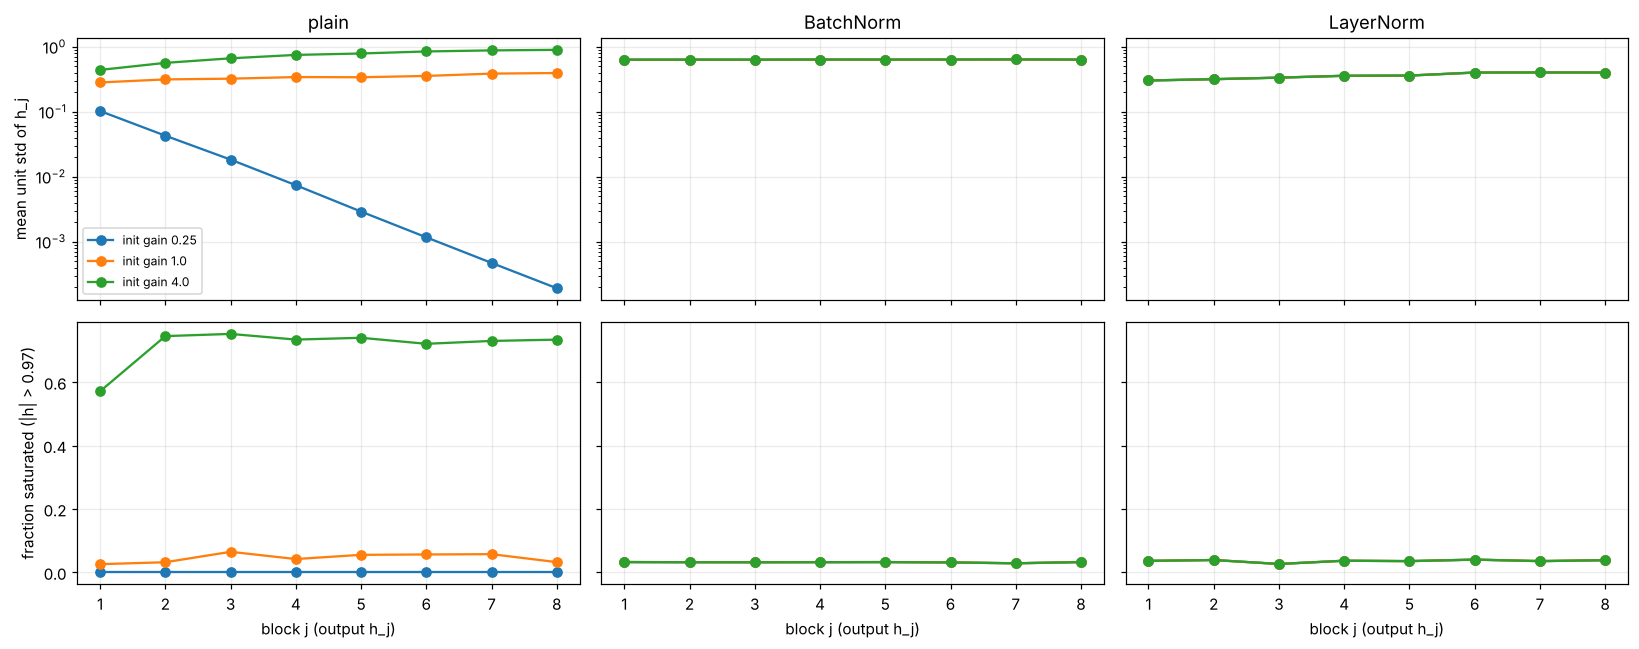

In [10]:
gains = [0.25, 1.0, 4.0]
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey="row")
for col, nm in enumerate(NAMES):
    for gnum in gains:
        m = new_model(nm, init_gain=gnum).train()
        with torch.no_grad():
            _, hs = m(PROBE_X, return_acts=True)
        axes[0, col].plot(range(1, 9), [h.std(0).mean().item() for h in hs[1:]], marker="o", label=f"init gain {gnum}")
        axes[1, col].plot(range(1, 9), [(h.abs() > 0.97).float().mean().item() for h in hs[1:]], marker="o", label=f"init gain {gnum}")
    axes[0, col].set_title(NAMES[nm]); axes[1, col].set_xlabel("block j (output h_j)")
axes[0, 0].set_ylabel("mean unit std of h_j"); axes[0, 0].set_yscale("log")
axes[1, 0].set_ylabel("fraction saturated (|h| > 0.97)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading it.** At initialization LN, like BN, makes the signal independent of the weight scale: the unit std and the saturated fraction are the same for init gains 0.25, 1 and 4 (the three LN curves lie on top of each other, at ~0.3-0.4 and ~4% saturated). The plain network is the opposite: at gain 0.25 the signal shrinks by a factor of about 500 by block 8 (1e-1 to 2e-4), and at gain 4 about 73% of the units are saturated. LN's `tanh` inputs always have unit scale (`gamma = 1`), which is why the curves coincide.

This is a statement about the *forward* signal at step 0. Whether training then works is a different question, answered next.

### 5c. Learning-rate tolerance and robustness to the initialization scale

Two sweeps (15 epochs, **3 seeds** per setting, SGD with momentum 0.9), final validation accuracy (chance is 0.10):

- **learning rate** from 0.01 to 1.0 with the standard initialization
- **initialization scale** from 0.25x to 4x at `lr = 0.05`

done in 35s


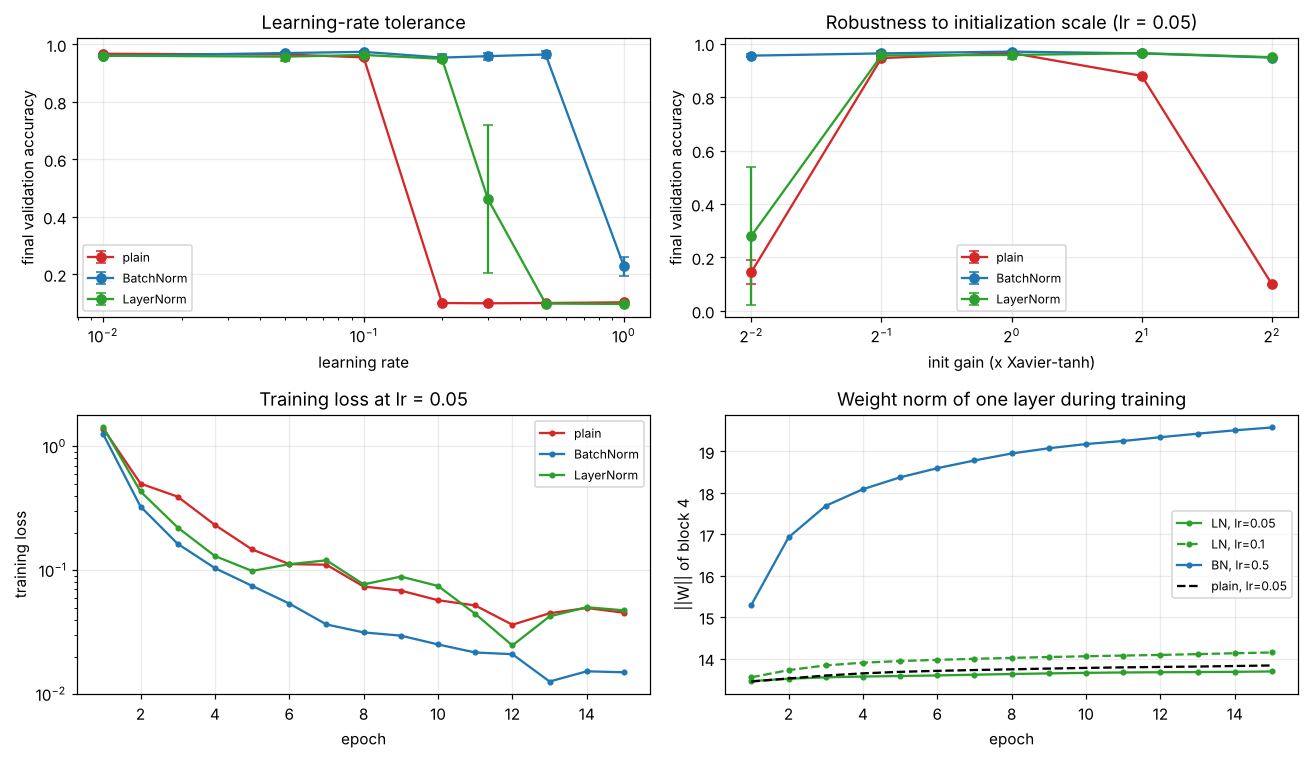

Final validation accuracy (mean of 3 seeds; chance = 0.10)
    lr |      plain  BatchNorm  LayerNorm
  0.01 |      0.967      0.960      0.961
  0.05 |      0.965      0.970      0.958
   0.1 |      0.955      0.974      0.963
   0.2 |      0.100      0.954      0.950
   0.3 |      0.099      0.959      0.463
   0.5 |      0.100      0.965      0.098
   1.0 |      0.102      0.227      0.097

  gain |      plain  BatchNorm  LayerNorm
  0.25 |      0.145      0.955      0.281
   0.5 |      0.946      0.963      0.956
   1.0 |      0.965      0.970      0.958
   2.0 |      0.879      0.963      0.964
   4.0 |      0.099      0.947      0.949

Epochs to reach 90% validation accuracy at lr = 0.05: {'plain': 4, 'BatchNorm': 2, 'LayerNorm': 3}


In [11]:
EPOCHS = 15
LRS = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
GAINS = [0.25, 0.5, 1.0, 2.0, 4.0]
SEEDS = (0, 1, 2)

t0 = time.time()
lr_runs = {(nm, lr): [fit(new_model(nm, seed=s), epochs=EPOCHS, lr=lr, seed=s) for s in SEEDS] for nm in NAMES for lr in LRS}
gain_runs = {(nm, gn): [fit(new_model(nm, seed=s, init_gain=gn), epochs=EPOCHS, lr=0.05, seed=s) for s in SEEDS] for nm in NAMES for gn in GAINS}
print(f"done in {time.time() - t0:.0f}s")
final_acc = lambda runs: np.mean([r["val_acc"][-1] for r in runs])

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for nm in NAMES:
    axes[0, 0].errorbar(LRS, [final_acc(lr_runs[(nm, lr)]) for lr in LRS], yerr=[np.std([r["val_acc"][-1] for r in lr_runs[(nm, lr)]]) for lr in LRS], marker="o", capsize=3, color=COL[nm], label=NAMES[nm])
    axes[0, 1].errorbar(GAINS, [final_acc(gain_runs[(nm, gn)]) for gn in GAINS], yerr=[np.std([r["val_acc"][-1] for r in gain_runs[(nm, gn)]]) for gn in GAINS], marker="o", capsize=3, color=COL[nm], label=NAMES[nm])
    axes[1, 0].plot(range(1, EPOCHS + 1), np.mean([r["train_loss"] for r in lr_runs[(nm, 0.05)]], 0), marker="o", ms=3, color=COL[nm], label=NAMES[nm])
for lr, ls in ((0.05, "-"), (0.1, "--")):
    axes[1, 1].plot(range(1, EPOCHS + 1), np.mean([r["wnorm"] for r in lr_runs[("ln", lr)]], 0), ls=ls, color="C2", marker="o", ms=3, label=f"LN, lr={lr}")
axes[1, 1].plot(range(1, EPOCHS + 1), np.mean([r["wnorm"] for r in lr_runs[("bn", 0.5)]], 0), color="C0", marker="o", ms=3, label="BN, lr=0.5")
axes[1, 1].plot(range(1, EPOCHS + 1), np.mean([r["wnorm"] for r in lr_runs[("none", 0.05)]], 0), "k--", label="plain, lr=0.05")
axes[0, 0].set_xscale("log"); axes[0, 0].set_xlabel("learning rate"); axes[0, 0].set_ylabel("final validation accuracy"); axes[0, 0].set_title("Learning-rate tolerance")
axes[0, 1].set_xscale("log", base=2); axes[0, 1].set_xlabel("init gain (x Xavier-tanh)"); axes[0, 1].set_ylabel("final validation accuracy"); axes[0, 1].set_title("Robustness to initialization scale (lr = 0.05)")
axes[1, 0].set_yscale("log"); axes[1, 0].set_xlabel("epoch"); axes[1, 0].set_ylabel("training loss"); axes[1, 0].set_title("Training loss at lr = 0.05")
axes[1, 1].set_xlabel("epoch"); axes[1, 1].set_ylabel("||W|| of block 4"); axes[1, 1].set_title("Weight norm of one layer during training")
for ax in axes.flat: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Final validation accuracy (mean of 3 seeds; chance = 0.10)")
print(f"{'lr':>6} | " + " ".join(f"{NAMES[nm]:>10}" for nm in NAMES))
for lr in LRS:
    print(f"{lr:>6} | " + " ".join(f"{final_acc(lr_runs[(nm, lr)]):>10.3f}" for nm in NAMES))
print(f"\n{'gain':>6} | " + " ".join(f"{NAMES[nm]:>10}" for nm in NAMES))
for gn in GAINS:
    print(f"{gn:>6} | " + " ".join(f"{final_acc(gain_runs[(nm, gn)]):>10.3f}" for nm in NAMES))


def epochs_to(acc, runs):
    m = np.mean([r["val_acc"] for r in runs], 0)
    hit = np.where(m >= acc)[0]
    return int(hit[0]) + 1 if len(hit) else None


print("\nEpochs to reach 90% validation accuracy at lr = 0.05:", {NAMES[nm]: epochs_to(0.9, lr_runs[(nm, 0.05)]) for nm in NAMES})

**Reading the sweeps** (3 seeds, final validation accuracy):

- **Learning rate.** With a tuned rate all three reach about 0.96 to 0.97, and the differences at lr 0.01-0.1 (0.955 to 0.974) are within what we would expect from seed noise on a 400-example validation set. They differ in how far the rate can go before training breaks: plain breaks at 0.2, **LN works up to 0.2** (0.950; at 0.3 it is unstable, 0.463 with a large spread across seeds, and at 0.5 it fails), BN works up to 0.5. So LN doubles the usable learning-rate range relative to plain, and BN is clearly better than LN on this axis.
- **Speed.** At lr = 0.05 the networks need 4 (plain), 3 (LN) and 2 (BN) epochs to reach 90% validation accuracy, and the loss curves show LN ahead of plain in the first ~6 epochs and about equal afterwards. The effect is small and comes with noisy curves; do not read much into the later epochs.
- **Initialization scale.** LN rescues the large gains (2 and 4: 0.964, 0.949, while plain falls to 0.879 and 0.099), but it **fails at gain 0.25** (0.281 with a huge spread), where BN is fine (0.955). That is an asymmetry, and the next section explains it.
- **Weight norm.** BN's weights grow steadily (15.3 to 19.6, at its high learning rate of 0.5), whereas LN's weights barely move (13.5 to 13.7 at lr 0.05) and are close to the plain network's.

### 5d. A closer look at the initialization result: weight scale acts like a learning rate

Why does LN fail with *small* initial weights (0.25x) but cope with *large* ones? Because of the scale invariance of section 4a. For a weight matrix `W` in front of a normalizer, the gradient scales like `1/||W||`, so the **effective step size relative to the weights is about `lr / ||W||^2`**. Initializing at gain `g` makes `||W||` about `g` times larger, so **the effective learning rate is `lr / g^2`**: small weights mean a large effective step. Our sweep at `lr = 0.05` with gain 0.25 therefore behaves like a learning rate of about `0.05 / 0.0625 = 0.8`, which we saw is far too large for LN.

If that is the right explanation, keeping the effective rate fixed, `lr = 0.05 * g^2`, should repair the small-gain failure. We test it for all three networks.

done in 14s


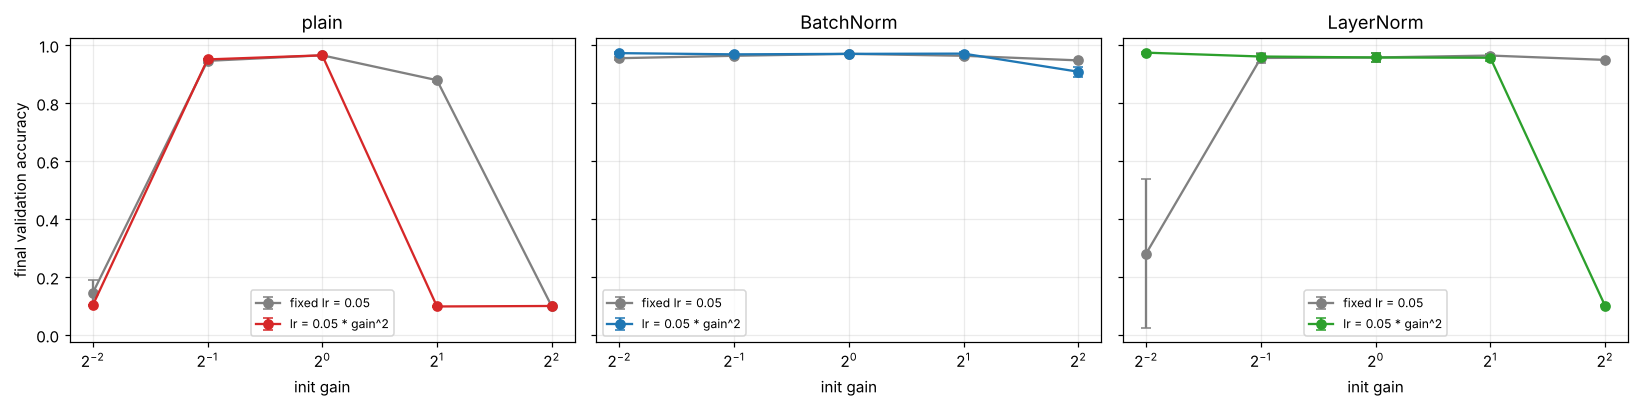

  gain  lr = 0.05*g^2 |     plain (fixed lr)     plain (scaled lr) BatchNorm (fixed lr) BatchNorm (scaled lr) LayerNorm (fixed lr) LayerNorm (scaled lr)
  0.25         0.0031 |                0.145                 0.102                0.955                 0.973                0.281                 0.974
   0.5         0.0125 |                0.946                 0.951                0.963                 0.968                0.956                 0.961
   1.0         0.0500 |                0.965                 0.965                0.970                 0.970                0.958                 0.958
   2.0         0.2000 |                0.879                 0.098                0.963                 0.971                0.964                 0.957
   4.0         0.8000 |                0.099                 0.100                0.947                 0.908                0.949                 0.101


In [12]:
t0 = time.time()
gain_scaled = {(nm, gn): [fit(new_model(nm, seed=s, init_gain=gn), epochs=EPOCHS, lr=0.05 * gn ** 2, seed=s) for s in SEEDS] for nm in NAMES for gn in GAINS}
print(f"done in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, nm in zip(axes, NAMES):
    ax.errorbar(GAINS, [final_acc(gain_runs[(nm, gn)]) for gn in GAINS], yerr=[np.std([r["val_acc"][-1] for r in gain_runs[(nm, gn)]]) for gn in GAINS], marker="o", capsize=3, color="gray", label="fixed lr = 0.05")
    ax.errorbar(GAINS, [final_acc(gain_scaled[(nm, gn)]) for gn in GAINS], yerr=[np.std([r["val_acc"][-1] for r in gain_scaled[(nm, gn)]]) for gn in GAINS], marker="o", capsize=3, color=COL[nm], label="lr = 0.05 * gain^2")
    ax.set_xscale("log", base=2); ax.set_xlabel("init gain"); ax.set_title(NAMES[nm]); ax.legend(fontsize=8)
axes[0].set_ylabel("final validation accuracy")
plt.tight_layout(); plt.show()
print(f"{'gain':>6} {'lr = 0.05*g^2':>14} | " + " ".join(f"{NAMES[nm] + ' (fixed lr)':>20} {NAMES[nm] + ' (scaled lr)':>21}" for nm in NAMES))
for gn in GAINS:
    print(f"{gn:>6} {0.05 * gn ** 2:>14.4f} | " + " ".join(f"{final_acc(gain_runs[(nm, gn)]):>20.3f} {final_acc(gain_scaled[(nm, gn)]):>21.3f}" for nm in NAMES))

**Reading it.** Matching the learning rate to the initialization (`lr = 0.05 * g^2`) removes the LN failure at gain 0.25: 0.281 becomes **0.974** (BN: 0.973), and gains 0.5, 1 and 2 are all between 0.957 and 0.961. So the small-gain failure was a learning-rate problem, and the `lr / ||W||^2` argument is the right explanation: a small initial weight matrix has a large effective step.

Two caveats. The repair does not extend to gain 4, where `lr = 0.8` is above what LN tolerates at any weight scale (0.101); and the plain network gets nothing from the rule (it is not scale-invariant), so this is specific to normalized layers. The practical message is that for LN (and BN) the initialization scale and the learning rate are **not independent knobs**: only their combination `lr / g^2` matters, so a value that is "too small" for one is "too large" for the other.

## 6. What LN buys that BN cannot

### 6a. Independence from the batch

We train a BN network and an LN network (20 epochs, `lr = 0.05`, 3 seeds) and keep them. For one fixed validation example we put it into 300 random batches of size `B` and look at how much its output (the logit of the true class) varies with its batch-mates, in `train()` mode (batch statistics for BN) and for LN, which has no separate mode. These are also the models used in section 6c.

trained 9 networks in 4s
final test accuracy (eval mode): {'plain': 0.96, 'BatchNorm': 0.971, 'LayerNorm': 0.982}


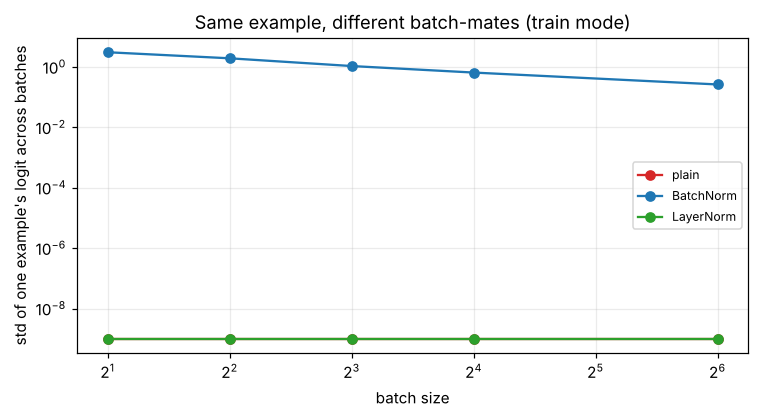

 batch size |        plain    BatchNorm    LayerNorm
          2 |     0.00e+00     3.06e+00     0.00e+00
          4 |     0.00e+00     1.93e+00     0.00e+00
          8 |     0.00e+00     1.07e+00     0.00e+00
         16 |     0.00e+00     6.51e-01     0.00e+00
         64 |     0.00e+00     2.63e-01     0.00e+00


In [13]:
t0 = time.time()
trained = {nm: [fit_m for fit_m in []] for nm in NAMES}
for nm in NAMES:
    for s in SEEDS:
        m = new_model(nm, seed=s)
        fit(m, epochs=20, lr=0.05, seed=s)
        trained[nm].append(m)
print(f"trained 9 networks in {time.time() - t0:.0f}s")
print("final test accuracy (eval mode):", {NAMES[nm]: round(float(np.mean([evaluate(m, Xte_t, yte_t)[1] for m in trained[nm]])), 3) for nm in NAMES})


@torch.no_grad()
def logit_spread(model, bs, n_batches=300, idx0=0):
    m = copy.deepcopy(model).train()
    rng = np.random.default_rng(0)
    others = np.setdiff1d(np.arange(len(Xva_t)), [idx0])
    vals = []
    for _ in range(n_batches):
        idx = np.concatenate([[idx0], rng.choice(others, bs - 1, replace=False)])
        vals.append(m(Xva_t[idx])[0, int(yva_t[idx0])].item())
    return np.std(vals)


BS2 = [2, 4, 8, 16, 64]
spread = {nm: [logit_spread(trained[nm][0], bs) for bs in BS2] for nm in ("none", "bn", "ln")}
fig, ax = plt.subplots(figsize=(7, 3.9))
for nm in ("none", "bn", "ln"):
    ax.plot(BS2, np.maximum(spread[nm], 1e-9), marker="o", color=COL[nm], label=NAMES[nm])
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("batch size"); ax.set_ylabel("std of one example's logit across batches"); ax.set_title("Same example, different batch-mates (train mode)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'batch size':>11} | " + " ".join(f"{NAMES[nm]:>12}" for nm in ("none", "bn", "ln")))
for i, bs in enumerate(BS2):
    print(f"{bs:>11} | " + " ".join(f"{spread[nm][i]:>12.2e}" for nm in ("none", "bn", "ln")))

**Reading it.** LN's output for a given example is exactly the same whatever it is batched with (spread 0, exactly, at every batch size), and so is the plain network's. BN's logit for the same example has a standard deviation of 3.1 across batches at batch size 2, shrinking steadily to 0.26 at 64. This is why BN needs running statistics and an `eval()` mode, and why it needs batches big enough to estimate its statistics well.

(The 20-epoch networks also give clean test accuracies of 0.960 / 0.971 / 0.982 for plain / BN / LN. With 397 test images the standard error is about 0.7 percentage points, and this is 3 seeds, so the ordering is suggestive at best; we do not claim that LN is the most accurate.)

### 6b. Training with small batches

BN's statistics get noisy when the batch is small. LN does not use the batch at all. We train all three networks with batch sizes from 2 to 256 (10 epochs, 3 seeds), scaling the learning rate with the batch size (`lr = 0.05 * batch / 64`, capped at 0.1) so that the number of steps does not confound the comparison, and evaluate in `eval()` mode.

done in 57s


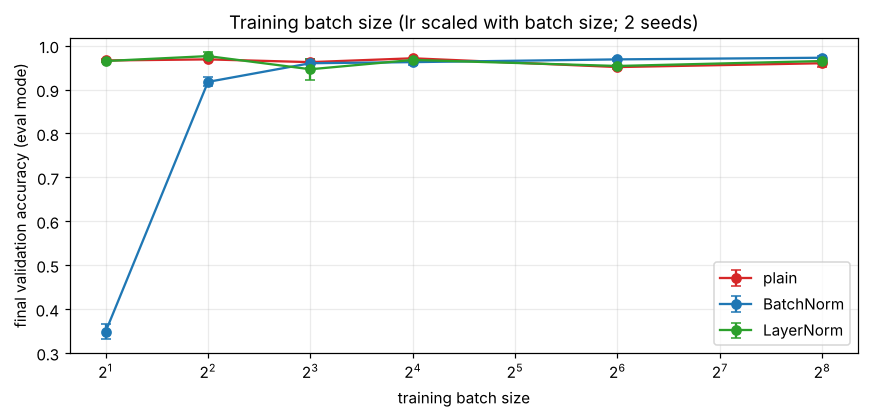

 batch       lr |      plain  BatchNorm  LayerNorm
     2   0.0016 |      0.966      0.349      0.965
     4   0.0031 |      0.969      0.918      0.976
     8   0.0063 |      0.962      0.960      0.946
    16   0.0125 |      0.971      0.963      0.967
    64   0.0500 |      0.951      0.969      0.954
   256   0.1000 |      0.960      0.972      0.965


In [14]:
TRAIN_BS = [2, 4, 8, 16, 64, 256]
lr_for = lambda bs: min(0.1, 0.05 * bs / 64)
t0 = time.time()
bs_runs = {(nm, bs): [fit(new_model(nm, seed=s), epochs=10, lr=lr_for(bs), batch_size=bs, seed=s) for s in (0, 1)] for nm in NAMES for bs in TRAIN_BS}
print(f"done in {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(8, 3.9))
for nm in NAMES:
    ax.errorbar(TRAIN_BS, [final_acc(bs_runs[(nm, bs)]) for bs in TRAIN_BS], yerr=[np.std([r["val_acc"][-1] for r in bs_runs[(nm, bs)]]) for bs in TRAIN_BS], marker="o", capsize=3, color=COL[nm], label=NAMES[nm])
ax.set_xscale("log", base=2); ax.set_xlabel("training batch size"); ax.set_ylabel("final validation accuracy (eval mode)"); ax.set_title("Training batch size (lr scaled with batch size; 2 seeds)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"{'batch':>6} {'lr':>8} | " + " ".join(f"{NAMES[nm]:>10}" for nm in NAMES))
for bs in TRAIN_BS:
    print(f"{bs:>6} {lr_for(bs):>8.4f} | " + " ".join(f"{final_acc(bs_runs[(nm, bs)]):>10.3f}" for nm in NAMES))

**Reading it.** BN degrades as the batch shrinks: 0.349 at batch size 2 and 0.918 at 4, with 0.96+ from 8 up. LN is flat across all sizes (0.946 to 0.976; the dip at 8 is within the noise, since plain has a similar wiggle: 0.951 to 0.971). Plain is flat too. The honest conclusion is that **LN removes BN's small-batch problem, but it does not do better than a plain network here**: with a small batch there is no batch statistic to lose, and our problem is easy enough that the plain net trains fine at these learning rates. The value of LN's batch independence shows up in settings where BN cannot be used (recurrent networks, sequences of varying length, very small per-device batches) and these are not covered by this experiment.

### 6c. Robustness to per-example input scale

Section 3 (panel iv) showed LN is exactly invariant to a per-example rescaling of the input, which in practice means differences in brightness, contrast or loudness between examples. BN (using the training statistics at test time) is not. We take the networks trained in 6a (clean training data, no scale changes) and test them on test images multiplied by a random factor `s_i = exp(rho * N(0,1))` each, for increasing `rho` (`rho = 1` means a typical factor of about 0.37x to 2.7x).

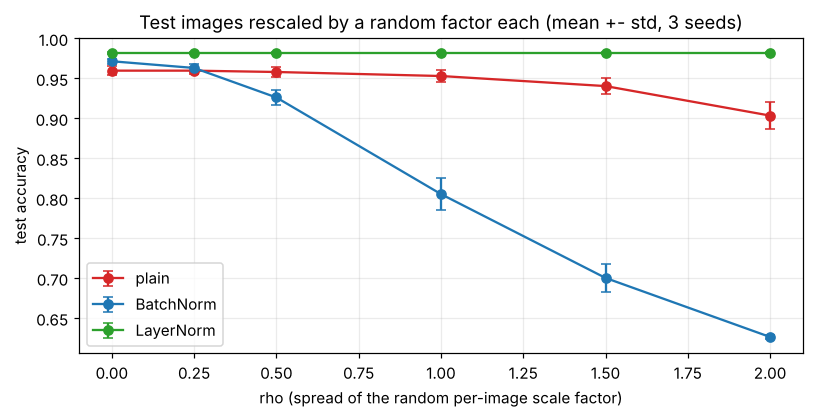

  rho |      plain  BatchNorm  LayerNorm
  0.0 |      0.960      0.971      0.982
 0.25 |      0.960      0.963      0.982
  0.5 |      0.958      0.926      0.982
  1.0 |      0.953      0.805      0.982
  1.5 |      0.940      0.700      0.982
  2.0 |      0.903      0.626      0.982


In [15]:
RHOS = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]
scale_acc = {}
for nm in NAMES:
    rows = []
    for rho in RHOS:
        g_ = torch.Generator().manual_seed(7)
        sc = torch.exp(rho * torch.randn(len(Xte_t), 1, generator=g_))
        rows.append([evaluate(m, Xte_t * sc, yte_t)[1] for m in trained[nm]])
    scale_acc[nm] = np.array(rows)

fig, ax = plt.subplots(figsize=(7.5, 3.9))
for nm in NAMES:
    ax.errorbar(RHOS, scale_acc[nm].mean(1), yerr=scale_acc[nm].std(1), marker="o", capsize=3, color=COL[nm], label=NAMES[nm])
ax.set_xlabel("rho (spread of the random per-image scale factor)"); ax.set_ylabel("test accuracy"); ax.set_title("Test images rescaled by a random factor each (mean +- std, 3 seeds)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"{'rho':>5} | " + " ".join(f"{NAMES[nm]:>10}" for nm in NAMES))
for i, rho in enumerate(RHOS):
    print(f"{rho:>5} | " + " ".join(f"{scale_acc[nm][i].mean():>10.3f}" for nm in NAMES))

**Reading it.** The LN networks' test accuracy is constant (0.982) at every `rho`, which is exactly what the invariance in section 3 says: a per-example rescaling of the input is divided out by the first LN layer, so the network sees the same thing. The BN networks lose accuracy steadily (0.971 to 0.626 at `rho = 2`), and the plain networks fall too (0.960 to 0.903), but more slowly than BN.

Two cautions. First, this is a robustness test where LN is *exactly* invariant by construction, so its success is expected rather than empirical evidence about real image brightness changes (and it holds only because the first layer has no bias: with a bias the invariance is only approximate). Second, it shows that BN can be *less* robust than not normalizing at all to changes of this type, because it fixes the per-unit statistics seen in training and the shifted inputs no longer match them.

## 7. Summary

| | Plain | BatchNorm | LayerNorm |
|---|---|---|---|
| Normalizes | nothing | each unit over the **batch** | each example over its **units** |
| Running statistics / train-eval difference | no | **yes** | no |
| Depends on batch-mates | no | **yes** | no |
| Invariant to weight scale | no | yes | yes |
| Invariant to per-unit bias shift | no | yes | **no** (only a shift shared by all units) |
| Invariant to per-example input scale | no | **no** | **yes** |
| Per-unit statistics stable in training (drift) | no (0.16) | **yes (0.007)** | no (0.18) |
| Per-example spread stable in training | no | yes | yes |
| Signal independent of init scale at step 0 | no | yes | yes |
| Highest learning rate that trains here | 0.1 | **0.5** | 0.2 |
| Fails at small init (gain 0.25) at fixed lr | yes | no | **yes** (fixed by `lr = 0.05 g^2`) |
| Fails at large init (gain 4) at fixed lr | yes | no | no |
| Small batches (2-4) | fine | **bad at 2** | fine |
| Final accuracy at a tuned learning rate | ~0.96 | ~0.97 | ~0.96 |

**What we found**

- LN normalizes along the other axis from BN, and this makes it **invariant to different things**: to per-example input scale and to weight scale, but not to per-unit offsets.
- LN makes learning **more robust**: the usable learning-rate range roughly doubles relative to plain (0.1 to 0.2), large initializations are repaired, and learning is a bit faster in the early epochs.
- LN **does not reproduce BN's main effect here**. It does not stabilize per-unit statistics (its drift score is the same as plain's), BN tolerates a 2.5x higher learning rate, and BN is faster.
- LN **does not improve accuracy at tuned settings** on this problem (all three are at 0.96-0.97).
- Initialization scale and learning rate are coupled for any normalized network through `lr / ||W||^2`.

**Caveats.** Small MLPs, one dataset (8x8 digits), SGD with momentum only, 2 to 3 seeds, a 400-example validation set. We did not try Adam, did not train a Transformer or an RNN (where LN is mostly used), and did not tune anything per method beyond the sweeps shown. The conclusions about which method is better should not be carried over to those settings; they are meant to show *mechanisms*.

**Exercises**

1. Give the preceding `Linear` layers a bias (`bias=True`) and repeat the per-example-scale test of 6c. How approximate does the invariance become, and how does it depend on the bias size?
2. Section 3 shows LN is not invariant to a per-unit bias shift. Subtract each unit's batch mean before LN and see which invariances you recover. What does that look like next to BN?
3. Train with Adam instead of SGD and repeat the learning-rate and init sweeps in 5c and 5d. Does the `lr / g^2` coupling survive?
4. Replace `tanh` with ReLU. Does the saturation story of 2b matter, and do the lr ranges change?
5. Add `GroupNorm` (with 8 groups of 8 units): it interpolates between LN (1 group) and per-unit normalization. Where does it land in the invariance table?